# Exploratory Data Analysis — Predictive Maintenance

**Goal of the project:** predict `maintenance_required` (0 = No, 1 = Yes) for 50 machines, so the company can raise an alert *before* a machine fails during a production run.

**What this notebook does**

| # | Section | Question it answers |
|---|---------|---------------------|
| 1 | Setup & first look | What is in the data? |
| 2 | Data quality | What is missing, wrong or duplicated — and how do we fix it? |
| 3 | Target variable | How balanced is `maintenance_required`? What does that mean for metrics? |
| 4 | Sensor distributions | What do the raw sensor readings look like? |
| 5 | Sensors vs target | Which sensors actually separate "maintenance" from "no maintenance"? |
| 6 | Derived columns & data leakage | How are the derived columns related to the target? Which are safe to use? |
| 7 | Machines & time | Do specific machines or times of day matter? Is there time-series structure? |
| 8 | Correlation & feature importance | Which features contribute most to the target? |
| 9 | Feature engineering | Which new features are justified by the EDA? |
| 10 | Summary | Key findings and decisions carried into the ML pipeline |

## 1. Setup & first look

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# ---- consistent, colour-blind-safe chart style ----
NO_COLOR, YES_COLOR, NEUTRAL = "#2a78d6", "#eb6834", "#8a8984"
TARGET_PALETTE = {0: NO_COLOR, 1: YES_COLOR}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
    "figure.dpi": 110,
})

DATA_PATH = "data/proj_machine_readings.csv"
SENSORS = ["temperature", "vibration", "humidity", "pressure", "energy_consumption"]
DERIVED = ["machine_status", "anomaly_flag", "predicted_remaining_life",
           "failure_type", "downtime_risk"]
TARGET = "maintenance_required"

In [2]:
df_raw = pd.read_csv(DATA_PATH, parse_dates=["timestamp"])
df = df_raw.copy()
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
df.head()

Rows: 100,000   Columns: 13


,timestamp,machine_id,temperature,vibration,humidity,pressure,energy_consumption,machine_status,anomaly_flag,predicted_remaining_life,failure_type,downtime_risk,maintenance_required
0,2025-01-01 00:00:00,39,NaN,-28.650,79.960,3.730,2.160,1,0,106,Normal,0.000,0
1,2025-01-01 00:01:00,29,68.190,57.280,35.940,3.640,0.690,1,0,320,Normal,0.000,0
2,2025-01-01 00:02:00,15,98.940,50.200,72.060,1.000,2.490,1,1,19,Normal,1.000,1
3,2025-01-01 00:03:00,43,90.910,37.650,30.340,3.150,4.960,1,1,10,Normal,1.000,1
4,2025-01-01 00:04:00,8,72.320,40.690,56.710,2.680,0.630,2,0,65,Vibration Issue,0.000,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 13 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   timestamp                 100000 non-null  datetime64[us]
 1   machine_id                100000 non-null  int64         
 2   temperature               86000 non-null   float64       
 3   vibration                 100000 non-null  float64       
 4   humidity                  100000 non-null  float64       
 5   pressure                  100000 non-null  float64       
 6   energy_consumption        100000 non-null  float64       
 7   machine_status            100000 non-null  int64         
 8   anomaly_flag              100000 non-null  int64         
 9   predicted_remaining_life  100000 non-null  int64         
 10  failure_type              100000 non-null  str           
 11  downtime_risk             100000 non-null  float64       
 12  maintenance_re

In [4]:
# Number of distinct values per column — tells us which columns are categorical in disguise
df.nunique().sort_values().to_frame("unique_values")

,unique_values
maintenance_required,2
anomaly_flag,2
machine_status,3
failure_type,5
downtime_risk,9
machine_id,50
pressure,401
energy_consumption,451
predicted_remaining_life,499
humidity,5001


In [5]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
timestamp,100000,2025-02-04 17:19:30,2025-01-01 00:00:00,2025-01-18 08:39:45,2025-02-04 17:19:30,2025-02-22 01:59:15,2025-03-11 10:39:00,NaN
machine_id,"100,000.000",25.499,1.000,13.000,25.000,38.000,50.000,14.389
temperature,"86,000.000",75.034,35.550,68.280,75.090,81.780,121.940,10.036
vibration,"100,000.000",43.324,-106.980,37.220,48.635,59.250,113.800,29.134
humidity,"100,000.000",54.995,30.000,42.520,54.980,67.500,80.000,14.438
pressure,"100,000.000",3.000,1.000,2.000,3.010,4.000,5.000,1.152
energy_consumption,"100,000.000",2.747,0.500,1.630,2.740,3.870,5.000,1.298
machine_status,"100,000.000",1.002,0.000,1.000,1.000,1.000,2.000,0.446
anomaly_flag,"100,000.000",0.089,0.000,0.000,0.000,0.000,1.000,0.285
predicted_remaining_life,"100,000.000",234.269,1.000,97.000,230.000,365.000,499.000,150.063


**First observations**

- 100,000 rows × 13 columns: one reading per minute from **2025-01-01 to 2025-03-11**, spread across 50 machines (~2,000 readings each).
- `machine_id`, `machine_status`, `anomaly_flag`, `failure_type` and `maintenance_required` are **categorical** even though most are stored as integers — `machine_id` in particular must not be treated as a number (machine 40 is not "twice" machine 20).
- `temperature` has only 86,000 non-null values → **14% missing**.
- `vibration` has a minimum of **−106.98 mm/s**. Vibration level is a magnitude and cannot be negative → data error to investigate.
- `humidity` (30–80%), `pressure` (1–5 bar) and `energy_consumption` (0.5–5 kWh) have very "clean" ranges and means sitting exactly in the middle — a hint that they may be close to uniformly distributed (checked in Section 4).
- `downtime_risk` takes only 9 distinct values and is almost always 0 or 1.

## 2. Data quality

### 2.1 Duplicates and timestamps

In [6]:
print("Fully duplicated rows:          ", df.duplicated().sum())
print("Duplicated rows (ignoring time):", df.drop(columns="timestamp").duplicated().sum())
print("Duplicated timestamps:          ", df["timestamp"].duplicated().sum())
print("Gaps between readings:\n", df["timestamp"].diff().value_counts())

Fully duplicated rows:           0
Duplicated rows (ignoring time): 0
Duplicated timestamps:           0
Gaps between readings:
 timestamp
0 days 00:01:00    99999
Name: count, dtype: int64


No duplicates. Every timestamp is unique and exactly **1 minute** apart — the factory logs one reading per minute, taken from one (random) machine at a time. So each machine is sampled irregularly, roughly every 50 minutes on average.

### 2.2 Missing values — `temperature`

In [7]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct_missing"] = missing["n_missing"] / len(df) * 100
missing[missing["n_missing"] > 0]

,n_missing,pct_missing
temperature,14000,14.000


Before choosing how to fill the gaps we need to know **why** they are missing. There are three textbook cases:

- **MCAR** (Missing Completely At Random) — the sensor randomly drops out. Safe to fill with a simple statistic.
- **MAR** (Missing At Random) — missingness depends on *other* columns (e.g. one machine's sensor is broken). Fill using those columns.
- **MNAR** (Missing Not At Random) — missingness depends on the value itself (e.g. sensor fails when it gets too hot). The fact that it is missing is itself information.

We test this by checking whether the missing rate changes with the target, machine, status or time.

In [8]:
df["temp_missing"] = df["temperature"].isna().astype(int)

checks = {
    "maintenance_required": df.groupby(TARGET)["temp_missing"].mean(),
    "anomaly_flag": df.groupby("anomaly_flag")["temp_missing"].mean(),
    "machine_status": df.groupby("machine_status")["temp_missing"].mean(),
}
for name, s in checks.items():
    print(f"Missing-temperature rate by {name}:\n{(s*100).round(2).to_string()}\n")

# chi-square test: is missingness independent of the target?
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df["temp_missing"], df[TARGET]))
print(f"Chi-square test (missing vs target): p-value = {p:.3f}")

Missing-temperature rate by maintenance_required:
maintenance_required
0   14.060
1   13.770

Missing-temperature rate by anomaly_flag:
anomaly_flag
0   14.020
1   13.770

Missing-temperature rate by machine_status:
machine_status
0   13.930
1   14.030
2   13.820

Chi-square test (missing vs target): p-value = 0.312


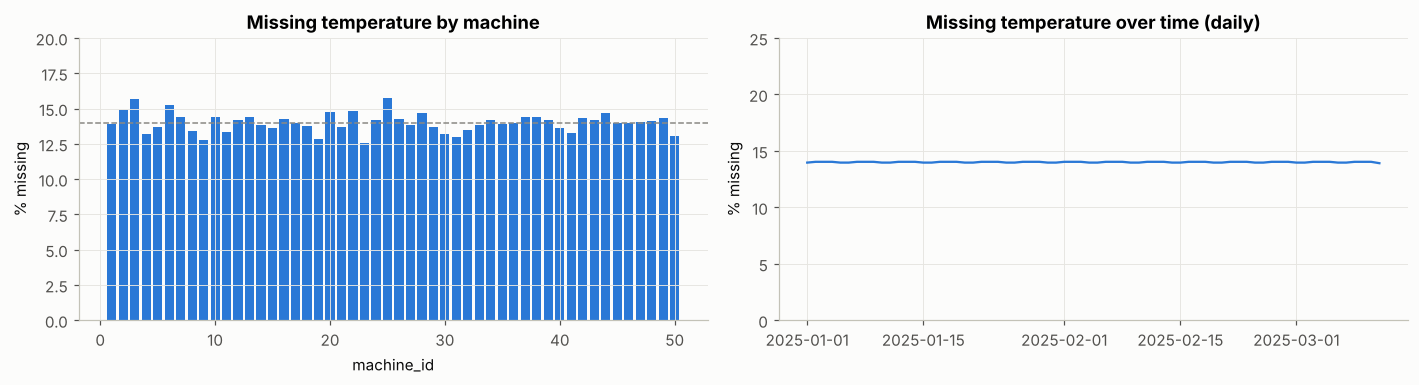

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
by_machine = df.groupby("machine_id")["temp_missing"].mean() * 100
axes[0].bar(by_machine.index, by_machine.values, color=NO_COLOR, width=0.8)
axes[0].axhline(by_machine.mean(), color=NEUTRAL, ls="--", lw=1)
axes[0].set(title="Missing temperature by machine", xlabel="machine_id", ylabel="% missing", ylim=(0, 20))

by_week = df.set_index("timestamp")["temp_missing"].resample("D").mean() * 100
axes[1].plot(by_week.index, by_week.values, color=NO_COLOR, lw=1.5)
axes[1].set(title="Missing temperature over time (daily)", ylabel="% missing", ylim=(0, 25))
plt.tight_layout(); plt.show()

In [10]:
# How related is temperature to the other numeric columns? (decides whether model-based imputation is worth it)
num_cols = SENSORS + ["predicted_remaining_life"]
df[num_cols].corr()["temperature"].drop("temperature").round(3).to_frame("corr_with_temperature")

,corr_with_temperature
vibration,-0.003
humidity,0.003
pressure,-0.001
energy_consumption,0.004
predicted_remaining_life,-0.195


**Insight — missing temperature is MCAR (completely random)**

- The missing rate is ~14% whether maintenance is required or not, for every machine (12.6–15.7%), every machine status, and every day. The chi-square test confirms missingness is independent of the target.
- So the dropouts look like a sensor/logging glitch, not something tied to machine health.

**Imputation decision**

- **Dropping rows is wasteful** — we would lose 14,000 rows (14%) of data whose other columns are perfectly fine.
- **Median imputation** is appropriate because the data are MCAR. The median is preferred over the mean because temperature has a long right tail (overheating readings up to 122 °C).
- A **per-machine median** adds nothing: all 50 machines have nearly identical average temperatures (shown in Section 7).
- **Model-based imputation** (KNN / iterative) adds little: temperature's strongest correlation with any other column is only −0.20 (with `predicted_remaining_life`).
- We also create a `temp_missing` indicator so the information "this reading was missing" is not lost after filling. Section 6.3 shows some missing readings hid overheating, but Section 8.3 shows the flag adds no measurable gain — it is cheap to keep and can be dropped later.
- In the pipeline, the median must be **learned from the training set only** and then applied to the test set, to avoid data leakage.

### 2.3 Invalid values — negative `vibration`

In [11]:
neg = df["vibration"] < 0
print(f"Negative vibration readings: {neg.sum():,} ({neg.mean()*100:.1f}% of rows)")
print(f"Affected machines: {df.loc[neg, 'machine_id'].nunique()} of 50")

compare = pd.DataFrame({
    "positive readings": df.loc[~neg, "vibration"].describe(),
    "|negative readings|": df.loc[neg, "vibration"].abs().describe(),
})
compare

Negative vibration readings: 6,703 (6.7% of rows)
Affected machines: 50 of 50


,positive readings,|negative readings|
count,"93,297.000","6,703.000"
mean,50.023,49.915
std,14.954,15.246
min,0.100,0.020
25%,39.960,40.025
50%,49.960,50.020
75%,60.110,60.050
max,113.800,106.980


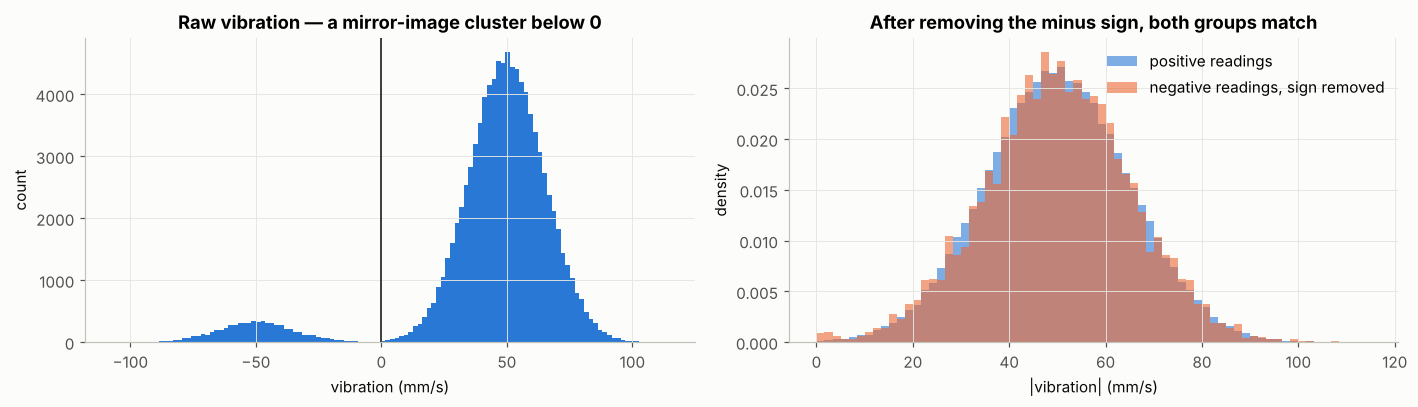

Kolmogorov–Smirnov test (same distribution?): statistic=0.010, p-value=0.575


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(df["vibration"], bins=120, color=NO_COLOR)
axes[0].axvline(0, color="#0b0b0b", lw=1)
axes[0].set(title="Raw vibration — a mirror-image cluster below 0", xlabel="vibration (mm/s)", ylabel="count")

bins = np.linspace(0, 115, 70)
axes[1].hist(df.loc[~neg, "vibration"], bins=bins, density=True, color=NO_COLOR, alpha=0.6, label="positive readings")
axes[1].hist(df.loc[neg, "vibration"].abs(), bins=bins, density=True, color=YES_COLOR, alpha=0.6, label="negative readings, sign removed")
axes[1].set(title="After removing the minus sign, both groups match", xlabel="|vibration| (mm/s)", ylabel="density")
axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()

ks = stats.ks_2samp(df.loc[~neg, "vibration"], df.loc[neg, "vibration"].abs())
print(f"Kolmogorov–Smirnov test (same distribution?): statistic={ks.statistic:.3f}, p-value={ks.pvalue:.3f}")

**Insight — negative vibration is a sign error, not noise**

- 6.7% of readings are negative, spread across all 50 machines.
- Vibration level (mm/s) is a magnitude, so a negative value is physically impossible.
- When we remove the minus sign, the negative readings have **the same distribution** as the positive ones (mean ≈ 50, std ≈ 15; KS test cannot tell them apart). If these were random garbage values, their shape would not match so neatly.
- The negative rows also have the same maintenance and anomaly rates as positive rows, so they are ordinary readings that were logged with a flipped sign.

**Fix:** take the absolute value, `vibration = |vibration|`. This keeps all 6,703 rows instead of throwing them away or treating them as missing.

In [13]:
df["vibration"] = df["vibration"].abs()

### 2.4 Outliers

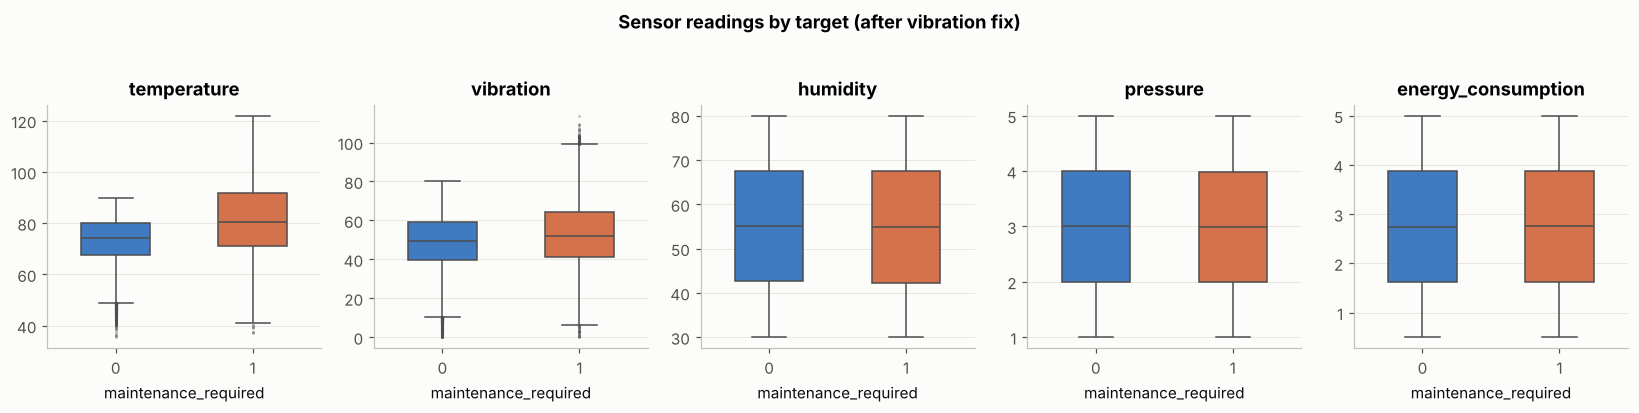

,IQR outliers,% needing maintenance (outliers)
feature,,
temperature,649,54.083
vibration,714,58.123
humidity,0,NaN
pressure,0,NaN
energy_consumption,0,NaN


In [14]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, col in zip(axes, SENSORS):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, ax=ax, palette=[NO_COLOR, YES_COLOR], legend=False, width=0.5,
                flierprops=dict(marker=".", markersize=2, alpha=0.3))
    ax.set(title=col, xlabel="maintenance_required", ylabel="")
plt.suptitle("Sensor readings by target (after vibration fix)", y=1.03, fontweight="bold")
plt.tight_layout(); plt.show()

def iqr_outlier_mask(s):
    # True where a value lies beyond 1.5 x IQR from the quartiles
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)

rows = []
for c in SENSORS:
    mask = iqr_outlier_mask(df[c])
    rows.append({"feature": c, "IQR outliers": int(mask.sum()),
                 "% needing maintenance (outliers)": df.loc[mask, TARGET].mean() * 100 if mask.any() else np.nan})
pd.DataFrame(rows).set_index("feature")

**Insight — keep the outliers**

- Only `temperature` and `vibration` have outliers; `humidity`, `pressure` and `energy_consumption` are bounded with none.
- More than half of the temperature (54%) and vibration (58%) outliers need maintenance, versus 20% overall — the high-end outliers are very hot or strongly vibrating machines. These extreme readings are exactly the signal we want the model to learn, so they are **not removed or capped**.
- Tree-based models are unaffected by outliers; for scale-sensitive models (e.g. logistic regression, SVM) we will scale features in the pipeline.

## 3. Target variable — `maintenance_required`

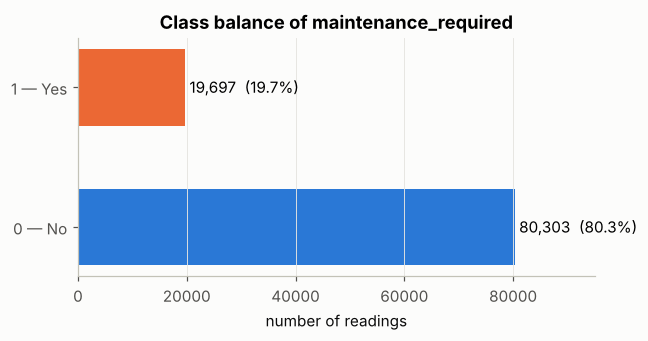

In [15]:
counts = df[TARGET].value_counts().sort_index()
pct = counts / counts.sum() * 100
fig, ax = plt.subplots(figsize=(6, 3.2))
bars = ax.barh(["0 — No", "1 — Yes"], counts.values, color=[NO_COLOR, YES_COLOR], height=0.55)
for b, c, p in zip(bars, counts.values, pct.values):
    ax.text(b.get_width() + 800, b.get_y() + b.get_height() / 2, f"{c:,}  ({p:.1f}%)", va="center")
ax.set(title="Class balance of maintenance_required", xlabel="number of readings", xlim=(0, 95000))
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Insight — the target is imbalanced (≈ 80 : 20)**

- About 1 in 5 readings needs maintenance. A "model" that always predicts *No* would already be 80% accurate while catching **zero** machines that need maintenance — so **accuracy is a misleading metric here**.

**Consequences for the pipeline**

- Use a **stratified** train/test split (and stratified cross-validation) so both sets keep the 80/20 ratio.
- Evaluate with **recall**, **precision**, **F1** and **PR-AUC**, not accuracy:
  - **Recall** (of the machines that need maintenance, how many did we catch?) is the most important — a missed alert means an unplanned breakdown during production, which is what the company wants to avoid.
  - **Precision** still matters — too many false alarms and the maintenance team will start ignoring the alerts.
  - **F1** balances both; PR-AUC summarises performance across all thresholds.
- Consider `class_weight="balanced"` (or similar) and tuning the decision threshold.

## 4. Sensor distributions (univariate)

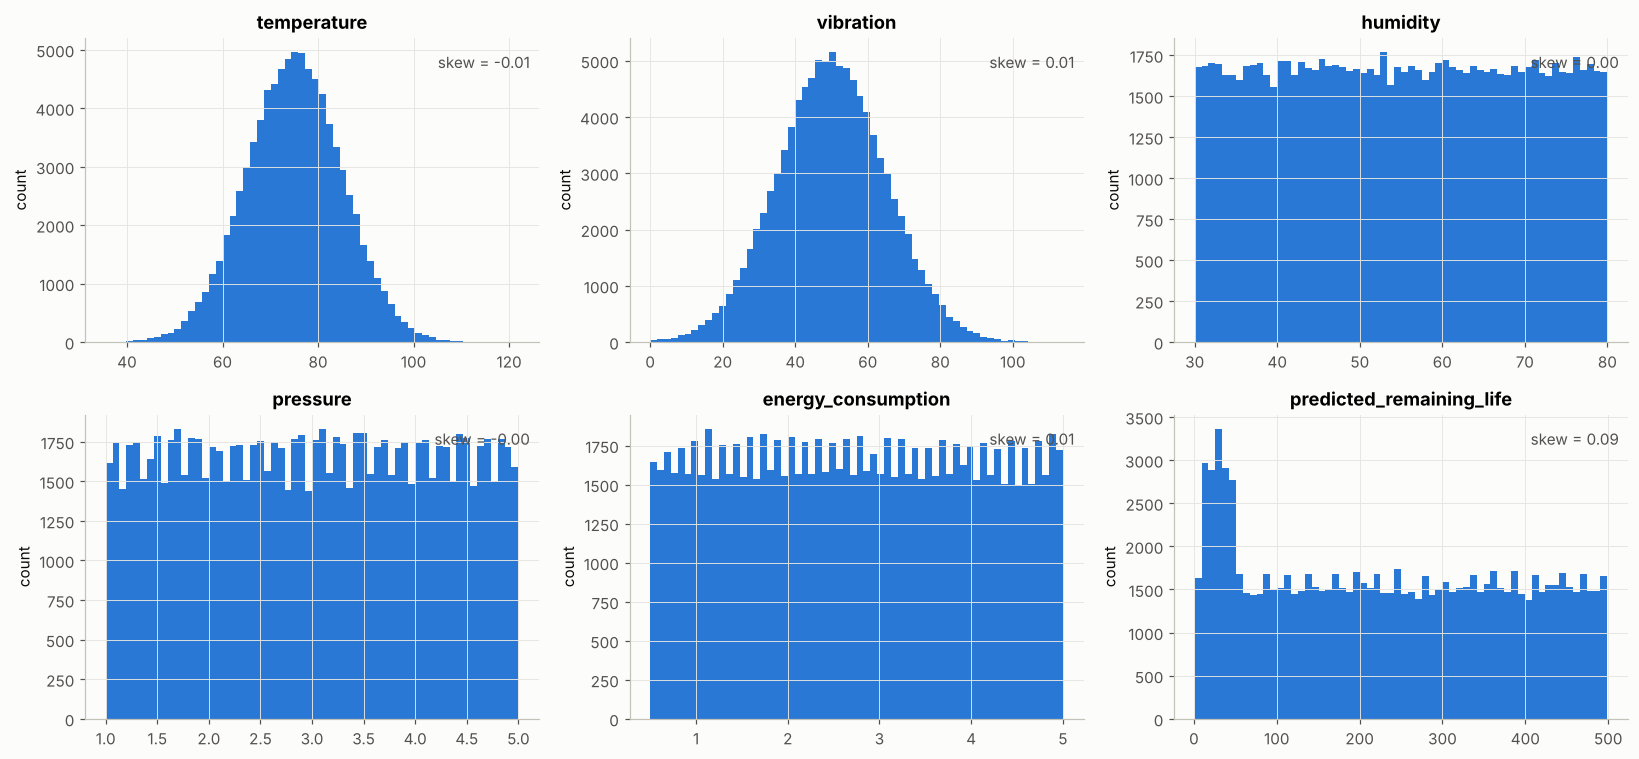

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, col in zip(axes.flat, SENSORS + ["predicted_remaining_life"]):
    ax.hist(df[col].dropna(), bins=60, color=NO_COLOR)
    ax.set(title=col, ylabel="count")
    ax.text(0.98, 0.95, f"skew = {df[col].skew():.2f}", transform=ax.transAxes, ha="right", va="top", color="#52514e")
plt.tight_layout(); plt.show()

**Insight**

- **temperature** — bell-shaped around 75 °C (std ≈ 10) with a right tail (overheating, up to 122 °C).
- **vibration** — bell-shaped around 50 mm/s (std ≈ 15) once the sign error is fixed; a light right tail of extreme vibration.
- **humidity, pressure, energy_consumption** — almost perfectly **flat (uniform)** across their ranges. Real sensors rarely look like this; it suggests these values are essentially random, which already hints they carry little information about machine health (confirmed in Section 5).
- **predicted_remaining_life** — uniform from 1 to 499 hours.

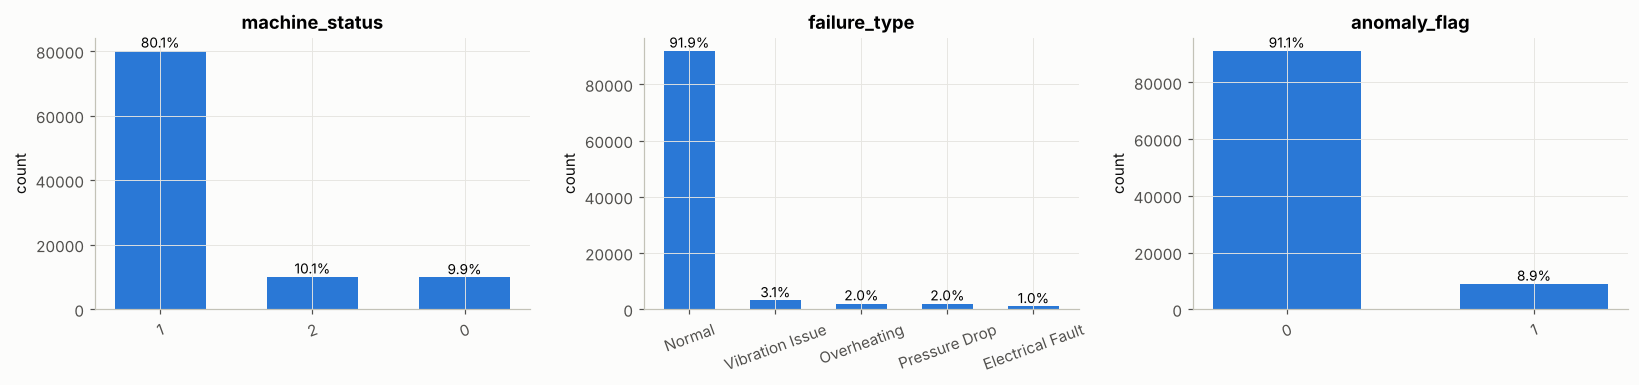

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col in zip(axes, ["machine_status", "failure_type", "anomaly_flag"]):
    vc = df[col].value_counts()
    ax.bar(vc.index.astype(str), vc.values, color=NO_COLOR, width=0.6)
    ax.set(title=col, ylabel="count"); ax.tick_params(axis="x", rotation=20)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v/len(df)*100:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

- **machine_status:** 80% running, 10% idle, 10% failure.
- **failure_type:** 92% "Normal". Vibration Issue (3.1%) is the most common fault, then Overheating, Pressure Drop and Electrical Fault (1.0%).
- **anomaly_flag:** 8.9% of readings are flagged as anomalous.

## 5. Sensors vs target (bivariate)

Box plots in 2.4 already showed temperature and vibration are higher when maintenance is required. To see *where* the risk starts, we plot the **maintenance rate within small bins** of each sensor — this shows thresholds much more clearly than averages.

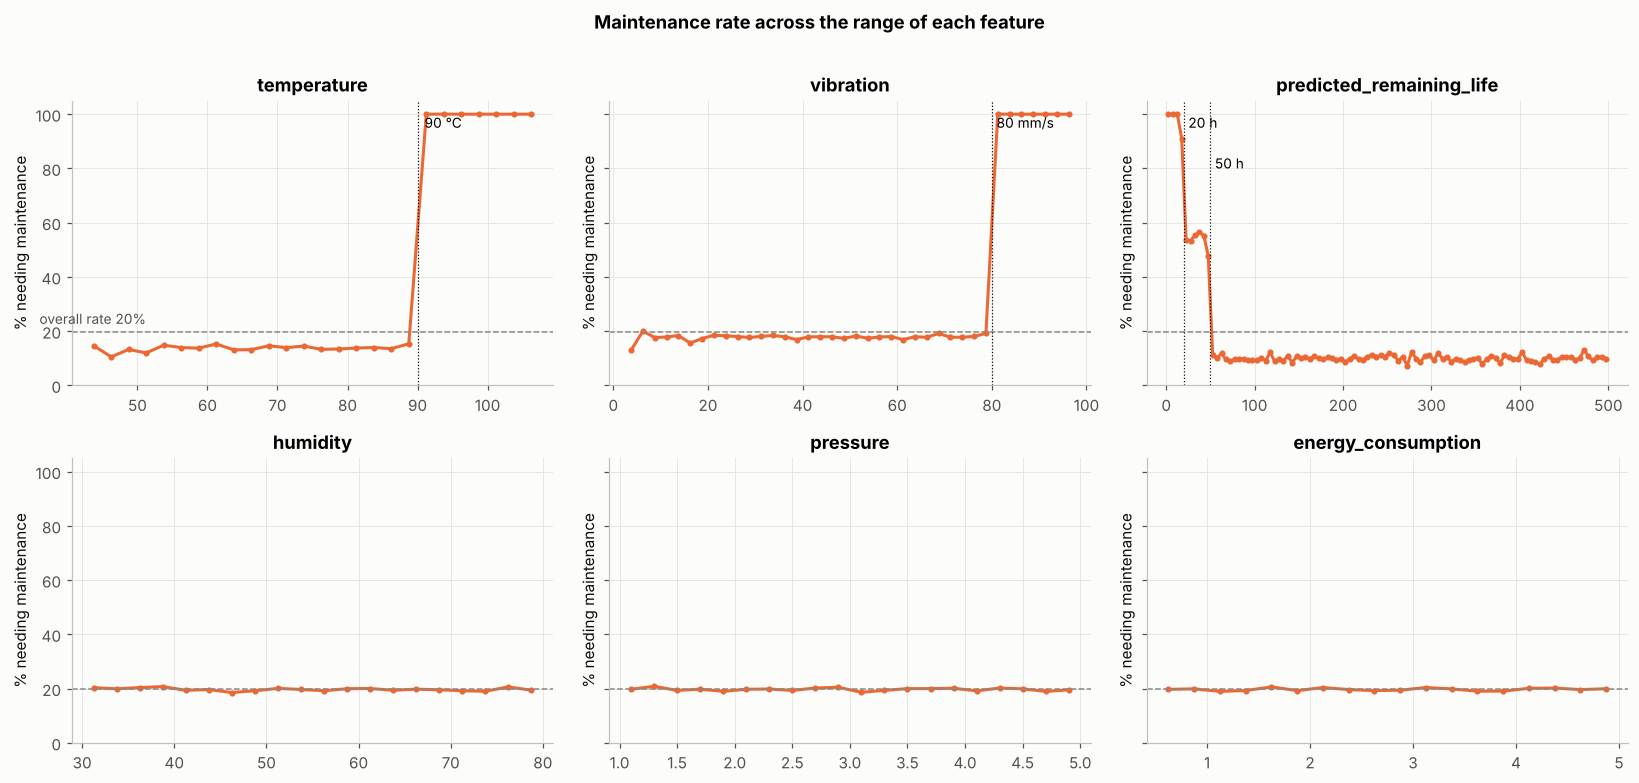

In [18]:
def rate_by_bin(col, bins):
    b = pd.cut(df[col], bins=bins)
    g = df.groupby(b, observed=True)[TARGET].agg(["mean", "size"])
    g = g[g["size"] >= 50]          # hide noisy bins with very few readings
    mids = [i.mid for i in g.index]
    return mids, g["mean"] * 100

specs = {
    "temperature": np.arange(35, 125, 2.5),
    "vibration": np.arange(0, 116, 2.5),
    "predicted_remaining_life": np.arange(0, 505, 5),
    "humidity": np.arange(30, 81, 2.5),
    "pressure": np.arange(1, 5.01, 0.2),
    "energy_consumption": np.arange(0.5, 5.01, 0.25),
}
base = df[TARGET].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharey=True)
for ax, (col, bins) in zip(axes.flat, specs.items()):
    x, y = rate_by_bin(col, bins)
    ax.plot(x, y, color=YES_COLOR, lw=2, marker="o", markersize=3)
    ax.axhline(base, color=NEUTRAL, ls="--", lw=1)
    ax.set(title=col, ylabel="% needing maintenance", ylim=(0, 105))
axes[0, 0].axvline(90, color="#0b0b0b", lw=0.8, ls=":"); axes[0, 0].text(91, 95, "90 °C", fontsize=9)
axes[0, 1].axvline(80, color="#0b0b0b", lw=0.8, ls=":"); axes[0, 1].text(81, 95, "80 mm/s", fontsize=9)
axes[0, 2].axvline(20, color="#0b0b0b", lw=0.8, ls=":"); axes[0, 2].text(25, 95, "20 h", fontsize=9)
axes[0, 2].axvline(50, color="#0b0b0b", lw=0.8, ls=":"); axes[0, 2].text(55, 80, "50 h", fontsize=9)
axes[0, 0].text(36, base + 3, f"overall rate {base:.0f}%", color="#52514e", fontsize=9)
plt.suptitle("Maintenance rate across the range of each feature", y=1.01, fontweight="bold")
plt.tight_layout(); plt.show()

In [19]:
# Statistical check: does each sensor's distribution differ between the two classes?
rows = []
for col in SENSORS + ["predicted_remaining_life"]:
    a, b = df.loc[df[TARGET] == 0, col].dropna(), df.loc[df[TARGET] == 1, col].dropna()
    u = stats.mannwhitneyu(a, b)
    r = stats.pointbiserialr(df[TARGET][df[col].notna()], df[col].dropna())
    rows.append({"feature": col, "median (no)": a.median(), "median (yes)": b.median(),
                 "point-biserial r": r.statistic, "Mann-Whitney p": u.pvalue})
pd.DataFrame(rows).set_index("feature").sort_values("point-biserial r", key=abs, ascending=False)

,median (no),median (yes),point-biserial r,Mann-Whitney p
feature,,,,
predicted_remaining_life,259.000,42.000,-0.343,0.000
temperature,74.230,80.655,0.283,0.000
vibration,49.530,51.900,0.113,0.000
humidity,55.010,54.850,-0.004,0.227
pressure,3.010,2.990,-0.002,0.539
energy_consumption,2.740,2.750,0.001,0.663


**Insight — only three numeric features carry signal, and they work through thresholds**

| Feature | What happens | Takeaway |
|---|---|---|
| `temperature` | Rate is flat (~15%) up to **90 °C**, then jumps to **100%** | Every reading above 90 °C needs maintenance |
| `vibration` | Flat (~18%) up to **80 mm/s**, then jumps to **100%** | Every reading above 80 mm/s needs maintenance |
| `predicted_remaining_life` | **100%** below 20 h; ~50–55% between 20–50 h; flat (~10%) above 50 h | Strongest single feature |
| `humidity`, `pressure`, `energy_consumption` | Flat line at the overall rate | **No relationship** with the target (Mann-Whitney p > 0.05) |

- The relationships are **step-shaped, not linear**. A linear model like logistic regression will struggle to capture "nothing happens until 90 °C, then everything happens" from the raw value. This motivates (a) tree-based models, which naturally learn thresholds, and (b) engineered threshold flags (Section 9) so linear models can use them too.
- Correlation coefficients understate these features for the same reason (correlation measures *straight-line* relationships).

## 6. Derived columns & data leakage

The problem statement says some columns are **derived** (calculated from other data). Derived columns can secretly contain the answer, which is called **data leakage**: the model looks brilliant in testing but is useless in real life because the "clue" it relies on isn't available in time (or *is* the answer). We check each derived column against the target.

### 6.1 Each derived column vs the target

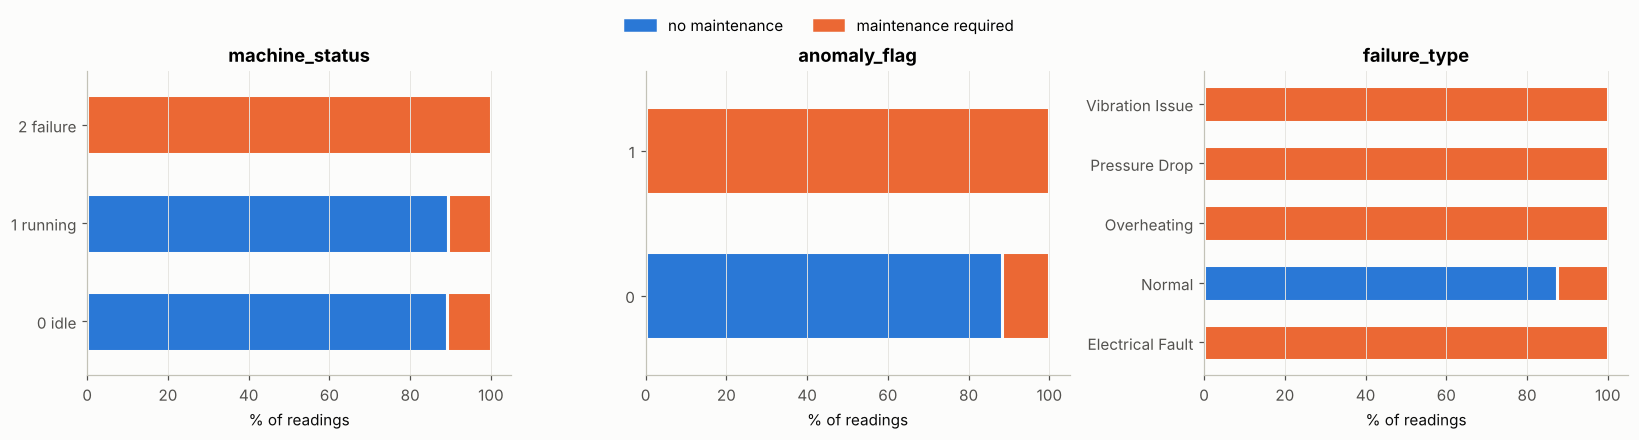

maintenance_required,0,1,All
machine_status,,,
0,8776,1076,9852
1,71527,8564,80091
2,0,10057,10057
All,80303,19697,100000


maintenance_required,0,1,All
anomaly_flag,,,
0,80303,10781,91084
1,0,8916,8916
All,80303,19697,100000


maintenance_required,0,1,All
failure_type,,,
Electrical Fault,0,1014,1014
Normal,80303,11596,91899
Overheating,0,1989,1989
Pressure Drop,0,1969,1969
Vibration Issue,0,3129,3129
All,80303,19697,100000


maintenance_required,0,1,All
downtime_risk,,,
0.000,80303,10781,91084
0.880,0,1,1
0.920,0,1,1
0.930,0,1,1
0.940,0,1,1
0.970,0,2,2
0.980,0,3,3
0.990,0,3,3
1.000,0,8904,8904


In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col in zip(axes, ["machine_status", "anomaly_flag", "failure_type"]):
    ct = pd.crosstab(df[col], df[TARGET], normalize="index") * 100
    ct.plot(kind="barh", stacked=True, ax=ax, color=[NO_COLOR, YES_COLOR], width=0.6, legend=False, edgecolor="#fcfcfb", linewidth=2)
    ax.set(title=f"{col}", xlabel="% of readings", ylabel="")
    ax.grid(axis="y", visible=False)
axes[0].set_yticklabels(["0 idle", "1 running", "2 failure"])
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in (NO_COLOR, YES_COLOR)]
fig.legend(handles, ["no maintenance", "maintenance required"], loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

for col in ["machine_status", "anomaly_flag", "failure_type", "downtime_risk"]:
    display(pd.crosstab(df[col], df[TARGET], margins=True))

Every time one of these is "bad", maintenance is **always** 1:

- `machine_status = 2` (failure) → 100% maintenance
- `anomaly_flag = 1` → 100% maintenance
- `failure_type` ≠ Normal → 100% maintenance
- `downtime_risk` > 0 → 100% maintenance

### 6.2 How the derived columns relate to each other

In [21]:
print("failure_type vs machine_status")
display(pd.crosstab(df["failure_type"], df["machine_status"]))
print("downtime_risk vs anomaly_flag")
display(pd.crosstab(df["downtime_risk"], df["anomaly_flag"]))

failure_type vs machine_status


machine_status,0,1,2
failure_type,,,
Electrical Fault,0,0,1014
Normal,9852,80091,1956
Overheating,0,0,1989
Pressure Drop,0,0,1969
Vibration Issue,0,0,3129


downtime_risk vs anomaly_flag


anomaly_flag,0,1
downtime_risk,,
0.000,91084,0
0.880,0,1
0.920,0,1
0.930,0,1
0.940,0,1
0.970,0,2
0.980,0,3
0.990,0,3
1.000,0,8904


- **`failure_type` is a subset of `machine_status = 2`.** Any non-Normal failure type only appears when the machine is in failure. It is a diagnosis made *after* the machine has broken down.
- **`downtime_risk` is a duplicate of `anomaly_flag`.** Risk is 0 for every non-anomaly and ≈1 (0.88–1.00) for every anomaly. It adds no new information.

### 6.3 Reverse-engineering the rules

The clean 100% splits suggest the target was produced by a simple rule. We test candidate rules exactly.

In [22]:
rul = df["predicted_remaining_life"]

# Rule for the TARGET
target_rule = (df["anomaly_flag"] == 1) | (df["machine_status"] == 2) | (rul < 20)
print("maintenance_required == anomaly OR failure status OR RUL < 20 ?")
display(pd.crosstab(target_rule.rename("rule"), df[TARGET]))
print(f"Rule matches {(target_rule.astype(int) == df[TARGET]).mean()*100:.2f}% of rows\n")

# Rule for the ANOMALY FLAG (uses sensors + RUL)
anom_rule = (rul < 50) & ((df["temperature"] > 90) | (df["vibration"] > 80) | (rul < 10))
print("anomaly_flag == RUL < 50 AND (temp > 90 OR |vibration| > 80 OR RUL < 10) ?")
display(pd.crosstab(anom_rule.rename("rule"), df["anomaly_flag"]))
unexplained = (df["anomaly_flag"] == 1) & ~anom_rule
print(f"Anomalies the rule misses: {unexplained.sum()} — of which temperature is missing: "
      f"{df.loc[unexplained, 'temperature'].isna().mean()*100:.1f}%")

maintenance_required == anomaly OR failure status OR RUL < 20 ?


maintenance_required,0,1
rule,,
False,80303,0
True,0,19697


Rule matches 100.00% of rows

anomaly_flag == RUL < 50 AND (temp > 90 OR |vibration| > 80 OR RUL < 10) ?


anomaly_flag,0,1
rule,,
False,91084,733
True,0,8183


Anomalies the rule misses: 733 — of which temperature is missing: 99.3%


**Insight — the target is fully determined by a rule**

$$\text{maintenance\_required} = \text{anomaly\_flag} \;\lor\; (\text{machine\_status}=2) \;\lor\; (\text{predicted\_remaining\_life} < 20)$$

This matches **100%** of the 100,000 rows. In turn, the anomaly flag is (almost exactly) a rule on the sensors:

$$\text{anomaly\_flag} = (\text{RUL} < 50) \;\land\; \big(\text{temp} > 90 \;\lor\; |\text{vibration}| > 80 \;\lor\; \text{RUL} < 10\big)$$

- The rule explains every non-anomaly and 8,183 of the 8,916 anomalies. **99.3% of the 733 anomalies it misses have a missing temperature** — almost certainly these readings were above 90 °C before the value was lost. This also confirms that the **vibration sign fix is correct**: the rule only works with `|vibration|`.
- The thresholds (90 °C, 80 mm/s, 20 h, 50 h) are the same ones visible in the Section 5 charts.

### 6.4 What sensors can and cannot see

In [23]:
pos = df[TARGET] == 1
s2, an, r20 = df["machine_status"] == 2, df["anomaly_flag"] == 1, rul < 20
reasons = pd.Series({
    "failure status ONLY": (pos & s2 & ~an & ~r20).sum(),
    "anomaly ONLY": (pos & an & ~s2 & ~r20).sum(),
    "RUL < 20 ONLY": (pos & r20 & ~s2 & ~an).sum(),
    "more than one reason": (pos & ((s2.astype(int) + an.astype(int) + r20.astype(int)) > 1)).sum(),
})
display((reasons.to_frame("rows").assign(pct_of_positives=lambda d: d["rows"] / pos.sum() * 100)))

print("\nAverage sensor readings by machine_status — do failing machines look different?")
display(df.groupby("machine_status")[SENSORS + ["predicted_remaining_life"]].mean())
print("Average sensor readings by failure_type")
display(df.groupby("failure_type")[SENSORS + ["predicted_remaining_life"]].mean())

,rows,pct_of_positives
failure status ONLY,8929,45.332
anomaly ONLY,4861,24.679
RUL < 20 ONLY,1648,8.367
more than one reason,4259,21.623



Average sensor readings by machine_status — do failing machines look different?


,temperature,vibration,humidity,pressure,energy_consumption,predicted_remaining_life
machine_status,,,,,,
0,75.134,49.770,54.884,2.996,2.764,234.548
1,75.015,50.052,55.011,3.002,2.746,234.380
2,75.094,49.965,54.977,2.996,2.738,233.110


Average sensor readings by failure_type


,temperature,vibration,humidity,pressure,energy_consumption,predicted_remaining_life
failure_type,,,,,,
Electrical Fault,75.463,48.970,55.219,2.987,2.795,225.289
Normal,75.021,50.027,54.977,3.001,2.747,234.429
Overheating,74.794,49.836,55.392,2.981,2.751,232.892
Pressure Drop,75.300,49.884,54.815,2.967,2.704,232.084
Vibration Issue,75.278,50.229,55.325,3.025,2.745,234.731


**Insight — failures are invisible to the sensors**

- **45%** of maintenance cases are flagged *only* because `machine_status = 2` (failure).
- Yet failing machines have the **same average temperature, vibration, pressure, energy and remaining life** as idle or running machines. Even an "Overheating" failure has an average temperature of 74.8 °C, and a "Pressure Drop" has normal pressure. In this dataset, failures are not preceded by any visible sensor change.

### 6.5 Leakage decision

| Column | Use as a feature? | Reason |
|---|---|---|
| `failure_type` | ❌ Drop | Only known *after* a failure has happened (a diagnosis). Using it to "predict" maintenance is circular. |
| `downtime_risk` | ❌ Drop | Exact duplicate of `anomaly_flag`. |
| `anomaly_flag` | ❌ Drop | Directly part of the target rule, and itself just a rule on temperature, vibration and RUL. The model can learn the same thresholds from those raw features, which are available in real time. |
| `machine_status` | ⚠️ Drop (recommended) | `status = 2` means the machine **has already failed** — the alert system is meant to warn *before* that. Including it would let the model "predict" failures by reading the failure. |
| `predicted_remaining_life` | ✅ Keep | An estimate available before failure; a legitimate early-warning signal and the strongest feature. |
| Sensor readings | ✅ Keep | Available in real time. |

**Why this matters (quantified in Section 8.3):** with `machine_status` the model scores ~0.98 F1 — but only by reading the answer. Without it, scores are lower (~0.69 F1, recall ≈ 53%), because the 45% "failure-only" cases cannot be detected from sensors. The team should present both numbers and explain the gap during the presentation; it is a strong talking point for the "choice of features/metrics" part of the rubric.

> **Team decision point:** if the group decides that `machine_status` *is* a live reading the machine would report (e.g. to alert on currently failed machines), it can be kept — but this must be justified explicitly in the README.

## 7. Machines & time

,readings,maintenance_rate,mean_temp,mean_vibration
mean,"2,000.000",0.197,75.036,50.017
std,51.673,0.009,0.235,0.295
min,"1,906.000",0.173,74.457,49.227
max,"2,092.000",0.215,75.655,50.659


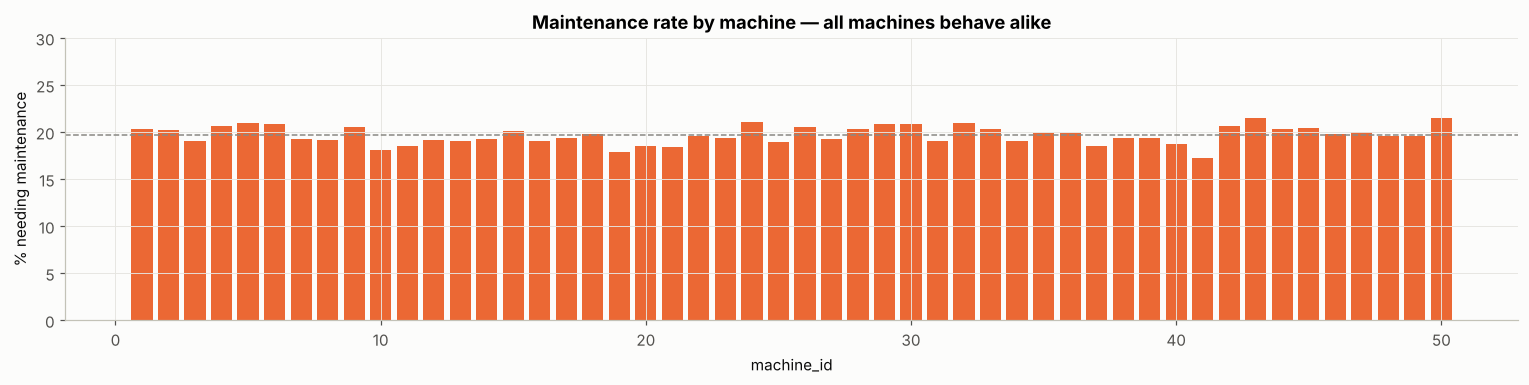

Chi-square test (machine_id vs target): p-value = 0.238


In [24]:
per_machine = df.groupby("machine_id").agg(
    readings=(TARGET, "size"), maintenance_rate=(TARGET, "mean"),
    mean_temp=("temperature", "mean"), mean_vibration=("vibration", "mean"))
display(per_machine.describe().loc[["mean", "std", "min", "max"]])

fig, ax = plt.subplots(figsize=(14, 3.6))
ax.bar(per_machine.index, per_machine["maintenance_rate"] * 100, color=YES_COLOR, width=0.8)
ax.axhline(base, color=NEUTRAL, ls="--", lw=1)
ax.set(title="Maintenance rate by machine — all machines behave alike", xlabel="machine_id", ylabel="% needing maintenance", ylim=(0, 30))
plt.tight_layout(); plt.show()

chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df["machine_id"], df[TARGET]))
print(f"Chi-square test (machine_id vs target): p-value = {p:.3f}")

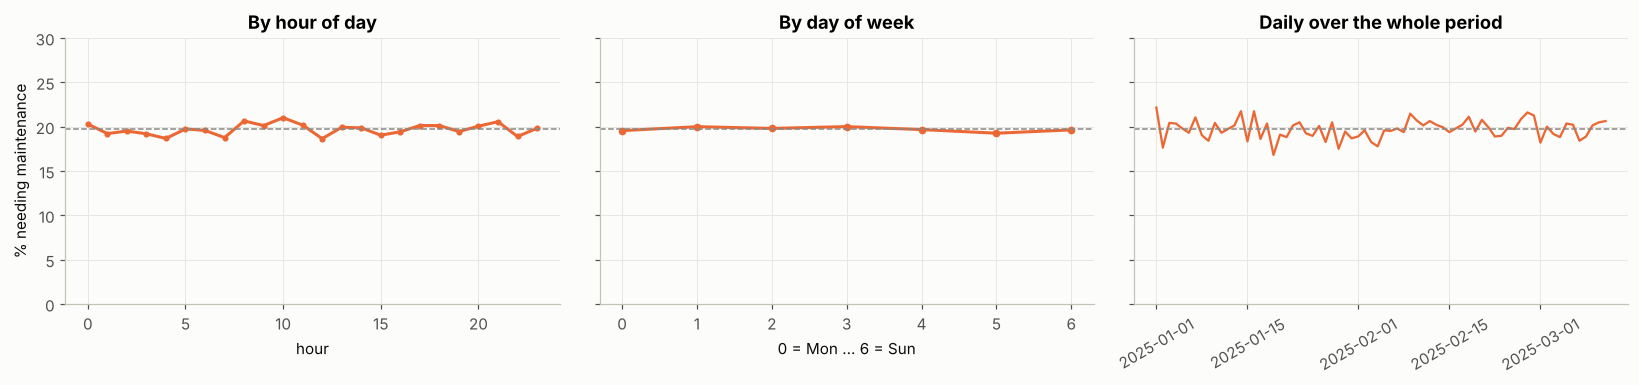

In [25]:
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
h = df.groupby("hour")[TARGET].mean() * 100
axes[0].plot(h.index, h.values, color=YES_COLOR, lw=2, marker="o", markersize=3)
axes[0].set(title="By hour of day", xlabel="hour", ylabel="% needing maintenance", ylim=(0, 30))
d = df.groupby("day_of_week")[TARGET].mean() * 100
axes[1].plot(d.index, d.values, color=YES_COLOR, lw=2, marker="o", markersize=4)
axes[1].set(title="By day of week", xlabel="0 = Mon … 6 = Sun", xticks=range(7))
w = df.set_index("timestamp")[TARGET].resample("D").mean() * 100
axes[2].plot(w.index, w.values, color=YES_COLOR, lw=1.5)
axes[2].set(title="Daily over the whole period"); axes[2].tick_params(axis="x", rotation=30)
for ax in axes: ax.axhline(base, color=NEUTRAL, ls="--", lw=1)
plt.tight_layout(); plt.show()

In [26]:
# Is there time-series memory? Lag-1 autocorrelation of each column within each machine
ordered = df.sort_values(["machine_id", "timestamp"])
acf = {c: ordered.groupby("machine_id")[c].apply(lambda s: s.autocorr(lag=1)).mean()
       for c in ["temperature", "vibration", "humidity", "pressure", "energy_consumption",
                 "predicted_remaining_life", TARGET]}
pd.Series(acf).round(3).to_frame("mean lag-1 autocorrelation (within machine)")

,mean lag-1 autocorrelation (within machine)
temperature,-0.003
vibration,0.002
humidity,-0.000
pressure,0.003
energy_consumption,0.003
predicted_remaining_life,0.002
maintenance_required,0.006


**Insight — no machine, time, or sequence effects**

- All 50 machines have nearly the same maintenance rate (17–22%), temperature and vibration. The chi-square test finds no machine effect → **`machine_id` is dropped** (one-hot encoding it would add 50 useless columns).
- Maintenance rate is flat by hour, day of week, and over the 10 weeks → **no time features** (hour, weekday, trend) are worth adding.
- Within a machine, each reading is unrelated to the previous one (autocorrelation ≈ 0, even for remaining life, which you would expect to count down steadily). Every row behaves like an **independent snapshot**, so lag or rolling-window features would only add noise.
- Because there is no time dependency, a **random stratified train/test split** is acceptable (a time-based split is not required, though it would also be fine).

## 8. Correlation & feature importance

### 8.1 Correlation matrix

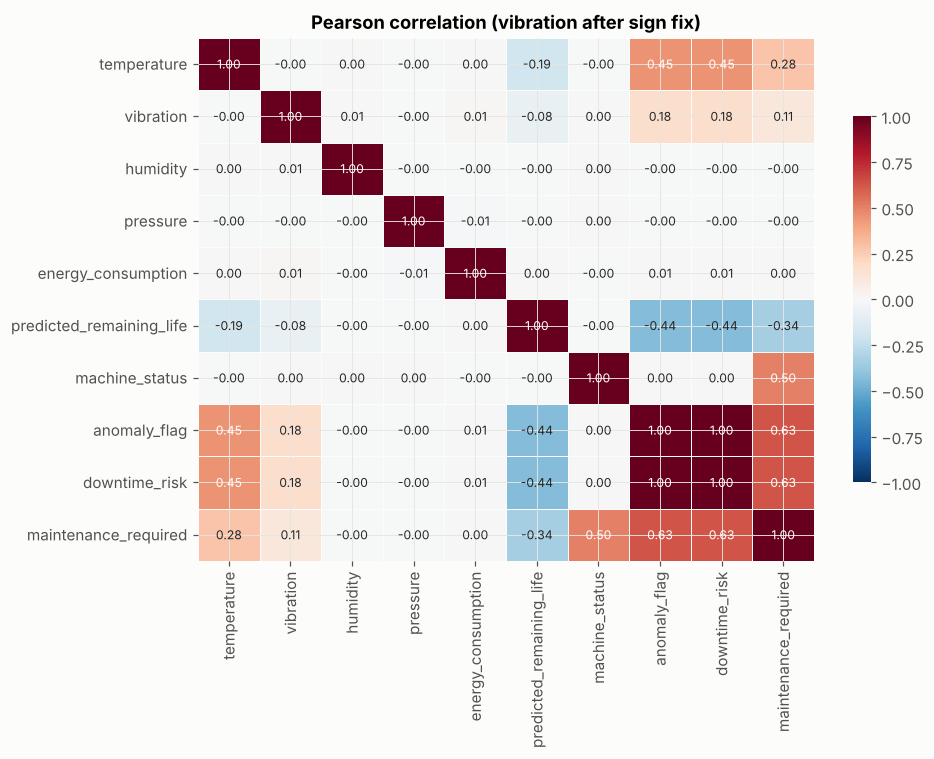

In [27]:
corr_cols = SENSORS + ["predicted_remaining_life", "machine_status", "anomaly_flag", "downtime_risk", TARGET]
corr = df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            linewidths=0.5, linecolor="#fcfcfb", cbar_kws={"shrink": 0.7}, ax=ax, annot_kws={"size": 8})
ax.set_title("Pearson correlation (vibration after sign fix)")
plt.tight_layout(); plt.show()

- The sensors are **not correlated with each other** (all |r| < 0.01) → no multicollinearity, no need to drop redundant sensors.
- `anomaly_flag` and `downtime_risk` correlate at **1.00** — confirming they are duplicates.
- `predicted_remaining_life` (−0.34) and `temperature` (+0.28) are the strongest non-leaky correlations with the target. Vibration looks weak (+0.11) only because its effect is a threshold, not a straight line.

### 8.2 Mutual information (captures non-linear relationships)

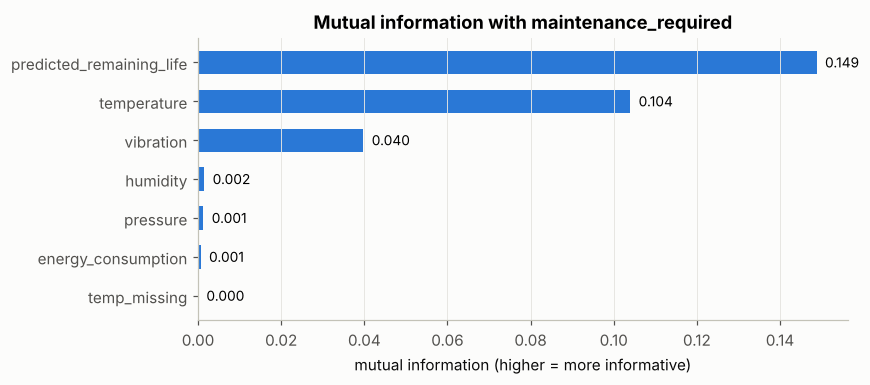

In [28]:
mi_df = df[SENSORS + ["predicted_remaining_life", "temp_missing"]].copy()
mi_df["temperature"] = mi_df["temperature"].fillna(mi_df["temperature"].median())
mi = mutual_info_classif(mi_df, df[TARGET], discrete_features=[False]*6 + [True], random_state=42)
mi = pd.Series(mi, index=mi_df.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(mi.index, mi.values, color=NO_COLOR, height=0.6)
for i, v in enumerate(mi.values): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=9)
ax.set(title="Mutual information with maintenance_required", xlabel="mutual information (higher = more informative)")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

Mutual information measures how much knowing a feature reduces uncertainty about the target, including non-linear patterns. Ranking: **predicted_remaining_life ≫ temperature > vibration**, while humidity, pressure, energy and the missing-temperature flag are ≈ 0.

### 8.3 How much can each feature set achieve? (quick baseline check)

This is not the final modelling — just a quick gradient-boosting model with 5-fold stratified CV, to measure how much signal each candidate feature set holds and to quantify the leakage.

In [29]:
X_base = df.copy()
X_base["temperature"] = X_base["temperature"].fillna(X_base["temperature"].median())

feature_sets = {
    "A. sensors only": SENSORS,
    "B. sensors + remaining life": SENSORS + ["predicted_remaining_life"],
    "C. B + temp_missing": SENSORS + ["predicted_remaining_life", "temp_missing"],
    "D. C + machine_status (leaky)": SENSORS + ["predicted_remaining_life", "temp_missing", "machine_status"],
    "E. all columns (leaky)": SENSORS + ["predicted_remaining_life", "temp_missing", "machine_status", "anomaly_flag", "downtime_risk"],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
results = {}
for name, cols in feature_sets.items():
    s = cross_validate(HistGradientBoostingClassifier(random_state=42), X_base[cols], df[TARGET], cv=cv,
                       scoring=["recall", "precision", "f1", "average_precision"])
    results[name] = {m: s[f"test_{m}"].mean() for m in ["recall", "precision", "f1", "average_precision"]}
pd.DataFrame(results).T.rename(columns={"average_precision": "PR-AUC"}).round(3)

,recall,precision,f1,PR-AUC
A. sensors only,0.407,0.988,0.576,0.611
B. sensors + remaining life,0.525,0.987,0.686,0.700
C. B + temp_missing,0.526,0.984,0.685,0.700
D. C + machine_status (leaky),0.983,0.989,0.986,1.000
E. all columns (leaky),1.000,1.000,1.000,1.000


**Insight**

- **Sensors only** catch some maintenance cases (via temperature > 90 °C and vibration > 80 mm/s).
- Adding **predicted_remaining_life** gives the biggest jump — it is the most important feature.
- Adding `machine_status` or `anomaly_flag` pushes scores close to perfect — this is the leakage from Section 6, not genuine predictive skill.
- With the honest feature set, **recall plateaus around 53%** (the theoretical maximum is ~55%, since 45% of positives are failure-only) and precision is close to 100%. `temp_missing` adds nothing measurable (B vs C). The remaining misses are almost all the "failure-only" cases from 6.4, which no sensor can see. Precision is very high because when the sensors *do* fire (hot, vibrating, low remaining life), maintenance is certain.

## 9. Feature engineering (justified by the EDA)

In [30]:
fe = df.copy()
fe["temperature"] = fe["temperature"].fillna(df["temperature"].median())   # in the pipeline: fit median on train only
fe["temp_over_90"] = (df["temperature"] > 90).astype(int)       # NaN counts as 0
fe["vibration_over_80"] = (df["vibration"] > 80).astype(int)
fe["rul_under_20"] = (df["predicted_remaining_life"] < 20).astype(int)
fe["rul_under_50"] = (df["predicted_remaining_life"] < 50).astype(int)
fe["sensor_alarm"] = ((fe["temp_over_90"] | fe["vibration_over_80"]) & fe["rul_under_50"]).astype(int)

new_feats = ["temp_missing", "temp_over_90", "vibration_over_80", "rul_under_20", "rul_under_50", "sensor_alarm"]
summary = pd.DataFrame({
    "% rows flagged": [fe[f].mean() * 100 for f in new_feats],
    "maintenance rate when flag=1 (%)": [fe.loc[fe[f] == 1, TARGET].mean() * 100 for f in new_feats],
    "maintenance rate when flag=0 (%)": [fe.loc[fe[f] == 0, TARGET].mean() * 100 for f in new_feats],
}, index=new_feats)
summary.round(1)

,% rows flagged,maintenance rate when flag=1 (%),maintenance rate when flag=0 (%)
temp_missing,14.000,19.400,19.700
temp_over_90,5.800,100.000,14.700
vibration_over_80,2.300,100.000,17.800
rul_under_20,5.300,100.000,15.200
rul_under_50,16.300,69.400,10.000
sensor_alarm,8.000,100.000,12.700


In [31]:
# Do the engineered flags help a simple linear model (which cannot learn thresholds by itself)?
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

raw = SENSORS + ["predicted_remaining_life"]
for name, cols in {"Logistic regression — raw features": raw,
                   "Logistic regression — raw + engineered flags": raw + new_feats}.items():
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced"))
    s = cross_validate(model, fe[cols], fe[TARGET], cv=cv, scoring=["recall", "precision", "f1"])
    print(f"{name:48s} recall={s['test_recall'].mean():.3f}  precision={s['test_precision'].mean():.3f}  f1={s['test_f1'].mean():.3f}")

Logistic regression — raw features               recall=0.679  precision=0.356  f1=0.467


Logistic regression — raw + engineered flags     recall=0.549  precision=0.941  f1=0.694


**Recommended engineered features**

| Feature | Definition | Why (EDA evidence) |
|---|---|---|
| `vibration` (fixed) | `abs(vibration)` | Negative values are a sign error (2.3); the anomaly rule only holds with \|vibration\| (6.3) |
| `temp_missing` *(optional)* | 1 if temperature was missing | Records that a value was filled in; some missing readings hid >90 °C anomalies (6.3), but the flag showed no gain in 8.3 — keep only if the final models benefit |
| `temp_over_90` | temperature > 90 °C | Maintenance rate jumps from ~17% to ~70% above 90 °C (5) |
| `vibration_over_80` | \|vibration\| > 80 mm/s | Same step pattern at 80 mm/s (5) |
| `rul_under_20` | remaining life < 20 h | 100% maintenance below 20 h (5, 6.3) |
| `rul_under_50` | remaining life < 50 h | Anomalies only occur below 50 h (6.3) |
| `sensor_alarm` | (temp > 90 or vib > 80) and RUL < 50 | Re-creates the anomaly logic from real-time features instead of using the leaky `anomaly_flag` |

- These flags turn the step-shaped relationships into something a **linear model** can use directly — the logistic regression above improves noticeably with them. Tree models can find these thresholds on their own, so for them the flags mainly speed up learning and make the model easier to explain.
- **Not engineered:** time features (hour/day) and lag/rolling features — Section 7 showed no time effect and no sequence memory. `machine_id` is dropped (no machine effect).
- `humidity`, `pressure` and `energy_consumption` show no signal. They can be kept for the first models (they are harmless to trees) and dropped later if feature importance confirms they add nothing.

## 10. Summary of key findings (for README.md)

**Data quality**
1. 100,000 readings, 50 machines, 1 reading/minute from 1 Jan to 11 Mar 2025. No duplicates.
2. **`temperature` is 14% missing, completely at random** (same rate across target, machines, statuses and time; chi-square p = 0.31). → Fill with the **median** (learned on the training set only), optionally with a `temp_missing` indicator. Rows are not dropped.
3. **6.7% of `vibration` values are negative**, which is physically impossible. Their absolute values follow the same distribution as positive readings → a **sign error**, fixed with `abs()`.
4. Outliers in temperature and vibration are **real overheating/vibration events** linked to maintenance → kept.

**Target**

5. `maintenance_required` is **imbalanced (80% No / 20% Yes)** → stratified splitting; evaluate with **recall** (most important: a missed alert means an unplanned breakdown), precision (to avoid alert fatigue), F1 and PR-AUC instead of accuracy.

**Feature relationships**

6. Only **predicted_remaining_life, temperature and vibration** relate to the target, and they do so through **thresholds**: RUL < 20 h, temperature > 90 °C and |vibration| > 80 mm/s all mean maintenance 100% of the time; RUL < 50 h raises the risk sharply. Humidity, pressure and energy consumption show **no relationship**.
7. Sensors are uncorrelated with each other → no multicollinearity.
8. No machine-specific, time-of-day, weekly or sequential patterns → `machine_id`, time and lag features are not used; rows can be treated independently.

**Leakage**

9. The target is exactly `anomaly_flag OR machine_status == 2 OR RUL < 20` (100% of rows). `anomaly_flag` is itself a threshold rule on temperature, vibration and RUL; `downtime_risk` duplicates `anomaly_flag`; `failure_type` only exists when the machine has already failed.
10. → **Drop `failure_type`, `downtime_risk`, `anomaly_flag` and (recommended) `machine_status`** to build a genuine early-warning model. Leaky features push F1 to ~0.98 without real predictive value.
11. 45% of maintenance cases come only from machines already in failure, whose sensor readings look completely normal. This caps the achievable recall of an honest sensor-based model at roughly 55% (baseline: recall 0.53, precision 0.99, F1 0.69).

**Carried into the pipeline**

| Step | Decision |
|---|---|
| Cleaning | `vibration = abs(vibration)`; median-impute `temperature` + `temp_missing` flag |
| Features | sensors, `predicted_remaining_life`, `temp_over_90`, `vibration_over_80`, `rul_under_20`, `rul_under_50`, `sensor_alarm` |
| Dropped | `timestamp`, `machine_id`, `failure_type`, `downtime_risk`, `anomaly_flag`, `machine_status` |
| Split | stratified train/test (e.g. 80/20), stratified k-fold CV for tuning |
| Models | tree-based models suit the threshold patterns (Decision Tree, Random Forest, Gradient Boosting); Logistic Regression as a baseline using the engineered flags |
| Metrics | recall, precision, F1, PR-AUC; consider class weights and threshold tuning |